# RNN, LSTM, and GRU for GOLD Closing price Forecasting

In [1]:
#import necessary libraries and tools
import pandas as pd
import numpy as np
import yfinance as yf
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler

In [2]:
# Loading the dataset of Gold for 10 years from 2010 to 2026
data = yf.download("GC=F", start="2010-01-01", end="2026-12-31")

/tmp/ipykernel_425/1895131588.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download("GC=F", start="2010-01-01", end="2026-12-31")
[*********************100%***********************]  1 of 1 completed


In [3]:
#explore head of data
data.head()

Price,Close,High,Low,Open,Volume
Ticker,GC=F,GC=F,GC=F,GC=F,GC=F
Date,,,,,
2010-01-04,1117.699951,1122.300049,1097.099976,1117.699951,184
2010-01-05,1118.099976,1126.500000,1115.000000,1118.099976,53
2010-01-06,1135.900024,1139.199951,1120.699951,1135.900024,363
2010-01-07,1133.099976,1133.099976,1129.199951,1133.099976,56
2010-01-08,1138.199951,1138.199951,1122.699951,1138.199951,54


In [4]:
# Remove the MultiIndex column level ('Ticker') and clean column names
data.columns = data.columns.droplevel('Ticker')
data.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2010-01-04,1117.699951,1122.300049,1097.099976,1117.699951,184
2010-01-05,1118.099976,1126.500000,1115.000000,1118.099976,53
2010-01-06,1135.900024,1139.199951,1120.699951,1135.900024,363
2010-01-07,1133.099976,1133.099976,1129.199951,1133.099976,56
2010-01-08,1138.199951,1138.199951,1122.699951,1138.199951,54


In [5]:
# Reset the index to make 'Date' a regular column instead of an index
data = data.reset_index()
display(data.head())

Price,Date,Close,High,Low,Open,Volume
0,2010-01-04,1117.699951,1122.300049,1097.099976,1117.699951,184
1,2010-01-05,1118.099976,1126.500000,1115.000000,1118.099976,53
2,2010-01-06,1135.900024,1139.199951,1120.699951,1135.900024,363
3,2010-01-07,1133.099976,1133.099976,1129.199951,1133.099976,56
4,2010-01-08,1138.199951,1138.199951,1122.699951,1138.199951,54


In [6]:
# Selecting numerical columns for normalization MIN, MAX so no domination for variables
numerical_cols = data.select_dtypes(include=['number']).columns
scaler = MinMaxScaler()
data[numerical_cols] = scaler.fit_transform(data[numerical_cols])

In [7]:
data.head()

Price,Date,Close,High,Low,Open,Volume
0,2010-01-04,0.015676,0.013328,0.012276,0.015011,0.000323
1,2010-01-05,0.015770,0.014257,0.016510,0.015103,0.000093
2,2010-01-06,0.019941,0.017064,0.017858,0.019182,0.000637
3,2010-01-07,0.019285,0.015715,0.019869,0.018540,0.000098
4,2010-01-08,0.020480,0.016843,0.018331,0.019709,0.000095


In [8]:
data.shape

(4228, 6)

In [9]:
def create_sequences(data, window_size, target_column=0):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i+window_size])
        y.append(data[i + window_size, target_column])
    return np.array(X), np.array(y)

seq_lengths = [10, 60, 120]
for seq_length in seq_lengths:
    X, y = create_sequences(data.drop('Date', axis=1).values, window_size=seq_length, target_column=0)
    print(f"Shape of X for sequence length {seq_length}: {X.shape}")
    print(f"Shape of y for sequence length {seq_length}: {y.shape}")

Shape of X for sequence length 10: (4218, 10, 5)
Shape of y for sequence length 10: (4218,)
Shape of X for sequence length 60: (4168, 60, 5)
Shape of y for sequence length 60: (4168,)
Shape of X for sequence length 120: (4108, 120, 5)
Shape of y for sequence length 120: (4108,)


(990,   10,   5)
  │      │    └── 5 features per day (columns)
  │      └─────── 10 days per window
  └────────────── 990 examples (windows)

In [10]:
#train and test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

In [11]:
#import sequential, Dense and Algorithms
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense

In [12]:
# Define the models
def create_simple_rnn(input_shape):
    model = Sequential()
    model.add(SimpleRNN(50, activation='relu', input_shape=input_shape)) #memory cell
    model.add(Dense(1))
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

def create_lstm(input_shape):
    model = Sequential()
    model.add(LSTM(50, activation='relu', input_shape=input_shape))
    model.add(Dense(1))
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

def create_gru(input_shape):
    model = Sequential()
    model.add(GRU(50, activation='relu', input_shape=input_shape))
    model.add(Dense(1))
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

## 10 Days

In [13]:
X_train.shape

(3286, 120, 5)

In [14]:
# Sequence length for 10 days
seq_length_10 = 10
input_shape_10 = (seq_length_10, X_train.shape[2]) #Remember that X_train.shape is (samples, days, features)

# Create and train models for 10 days
simple_rnn_model_10 = create_simple_rnn(input_shape_10)
history_rnn_10 = simple_rnn_model_10.fit(X_train, y_train, epochs=10, batch_size=64, validation_split=0.2)

lstm_model_10 = create_lstm(input_shape_10)
history_lstm_10 = lstm_model_10.fit(X_train, y_train, epochs=10, batch_size=64, validation_split=0.2)

gru_model_10 = create_gru(input_shape_10)
history_gru_10 = gru_model_10.fit(X_train, y_train, epochs=10, batch_size=64, validation_split=0.2)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - loss: 0.0012 - mae: 0.0220 - val_loss: 2.0290e-04 - val_mae: 0.0117
Epoch 2/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 3.5188e-05 - mae: 0.0040 - val_loss: 9.9397e-05 - val_mae: 0.0084
Epoch 3/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 1.9694e-05 - mae: 0.0030 - val_loss: 5.0534e-05 - val_mae: 0.0056
Epoch 4/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 1.8698e-05 - mae: 0.0030 - val_loss: 1.0382e-04 - val_mae: 0.0087
Epoch 5/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 1.7791e-05 - mae: 0.0028 - val_loss: 4.5077e-05 - val_mae: 0.0053
Epoch 6/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 1.7270e-05 - mae: 0.0029 - val_loss: 3.7763e-05 - val_mae: 0.0049
Epoch 7/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 1.5855e-05 - mae: 0.0027 - val_loss: 4.0258e-05 - val_mae: 0.0050
Epoch 8/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 1.5877e-05 - mae: 0.0027 - val_loss: 3.6371e-05 - val_mae: 0.0047
Epoc

In [15]:
# Evaluation
# store results
results_10 = {}

# Evaluate models
test_mse_rnn_10, test_mae_rnn_10 = simple_rnn_model_10.evaluate(X_test, y_test)
test_mse_lstm_10, test_mae_lstm_10 = lstm_model_10.evaluate(X_test, y_test)
test_mse_gru_10, test_mae_gru_10 = gru_model_10.evaluate(X_test, y_test)

results_10["simple_rnn_10"] = (test_mse_rnn_10, test_mae_rnn_10)
results_10["lstm_10"] = (test_mse_lstm_10, test_mae_lstm_10)
results_10["gru_10"] = (test_mse_gru_10, test_mae_gru_10)

# Print evaluation results for 10 days
print("Simple RNN (10) - Test MSE:", test_mse_rnn_10, "|Test MAE",test_mae_rnn_10)
print("LSTM (10) - Test MSE:", test_mse_lstm_10, "|Test MAE",test_mae_lstm_10)
print("GRU (10) - Test MSE:", test_mse_gru_10, "|Test MAE:", test_mae_gru_10)

26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0053 - mae: 0.0565
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0018 - mae: 0.0255    
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0153 - mae: 0.0917
Simple RNN (10) - Test MSE: 0.005252538714557886 |Test MAE 0.056538522243499756
LSTM (10) - Test MSE: 0.0017794676823541522 |Test MAE 0.025460658594965935
GRU (10) - Test MSE: 0.015262717381119728 |Test MAE: 0.09166091680526733


In [16]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Define a function to calculate evaluation metrics
def calculate_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    r_squared = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred.flatten()) / y_true)) * 100
    smape = np.mean(2 * np.abs(y_pred.flatten() - y_true) / (np.abs(y_true) + np.abs(y_pred.flatten()))) * 100

    return mse, mae, r_squared, mape, smape

In [17]:
# Make predictions and calculate metrics for 10 days models
y_pred_rnn_10 = simple_rnn_model_10.predict(X_test)
y_pred_lstm_10 = lstm_model_10.predict(X_test)
y_pred_gru_10 = gru_model_10.predict(X_test)

# Calculate metrics for each model
mse_rnn_10, mae_rnn_10, r2_rnn_10, mape_rnn_10, smape_rnn_10 = calculate_metrics(y_test, y_pred_rnn_10)
mse_lstm_10, mae_lstm_10, r2_lstm_10, mape_lstm_10, smape_lstm_10 = calculate_metrics(y_test, y_pred_lstm_10)
mse_gru_10, mae_gru_10, r2_gru_10, mape_gru_10, smape_gru_10 = calculate_metrics(y_test, y_pred_gru_10)

# Store the results for 10 days
results_10['simple_rnn_10_metrics'] = (mse_rnn_10, mae_rnn_10, r2_rnn_10, mape_rnn_10, smape_rnn_10)
results_10['lstm_10_metrics'] = (mse_lstm_10, mae_lstm_10, r2_lstm_10, mape_lstm_10, smape_lstm_10)
results_10['gru_10_metrics'] = (mse_gru_10, mae_gru_10, r2_gru_10, mape_gru_10, smape_gru_10)

# Print metrics for each model with 10 days
print(f"Simple RNN (10) - MSE: {mse_rnn_10}, MAE: {mae_rnn_10}, R2: {r2_rnn_10}, MAPE: {mape_rnn_10}, sMAPE: {smape_rnn_10}")
print(f"LSTM (10) - MSE: {mse_lstm_10}, MAE: {mae_lstm_10}, R2: {r2_lstm_10}, MAPE: {mape_lstm_10}, sMAPE: {smape_lstm_10}")
print(f"GRU (10) - MSE: {mse_gru_10}, MAE: {mae_gru_10}, R2: {r2_gru_10}, MAPE: {mape_gru_10}, sMAPE: {smape_gru_10}")

26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step
Simple RNN (10) - MSE: 0.005252538665894761, MAE: 0.05653852063342864, R2: 0.9027653361978394, MAPE: 9.43788712135424, sMAPE: 10.045609388324184
LSTM (10) - MSE: 0.0017794676389111487, MAE: 0.025460660328844486, R2: 0.9670586075377561, MAPE: 4.092465443546519, sMAPE: 3.9865237476828312
GRU (10) - MSE: 0.015262717101424008, MAE: 0.09166091167986083, R2: 0.7174575456815522, MAPE: 14.19221879907889, sMAPE: 15.795107844356643


## 60 Days

In [18]:
# Sequence length for 60 days
seq_length_60 = 60
input_shape_60 = (seq_length_60, X_train.shape[2])

# Training for 60 days
simple_rnn_model_60 = create_simple_rnn(input_shape_60)
history_rnn_60 = simple_rnn_model_60.fit(X_train, y_train, epochs=10, batch_size=64, validation_split=0.2)

lstm_model_60 = create_lstm(input_shape_60)
history_lstm_60 = lstm_model_60.fit(X_train, y_train, epochs=10, batch_size=64, validation_split=0.2)

gru_model_60 = create_gru(input_shape_60)
history_gru_60 = gru_model_60.fit(X_train, y_train, epochs=10, batch_size=64, validation_split=0.2)

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - loss: 7.3315e-04 - mae: 0.0161 - val_loss: 1.9705e-04 - val_mae: 0.0113
Epoch 2/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 4.8321e-05 - mae: 0.0047 - val_loss: 1.2569e-04 - val_mae: 0.0090
Epoch 3/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 4.1047e-05 - mae: 0.0044 - val_loss: 1.0750e-04 - val_mae: 0.0082
Epoch 4/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 3.5866e-05 - mae: 0.0041 - val_loss: 9.2946e-05 - val_mae: 0.0076
Epoch 5/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 3.3572e-05 - mae: 0.0040 - val_loss: 1.0919e-04 - val_mae: 0.0082
Epoch 6/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 3.2219e-05 - mae: 0.0039 - val_loss: 8.5771e-05 - val_mae: 0.0074
Epoch 7/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 2.7707e-05 - mae: 0.0036 - val_loss: 8.9510e-05 - val_mae: 0.0074
Epoch 8/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 2.8386e-05 - mae: 0.0036 - val_loss: 8.5945e-05 - val_mae: 0.0072
Epoch 9/10


In [19]:
# Evaluation
# store results
results_60 = {}

# Evaluate models
test_mse_rnn_60, test_mae_rnn_60 = simple_rnn_model_60.evaluate(X_test, y_test)
test_mse_lstm_60, test_mae_lstm_60 = lstm_model_60.evaluate(X_test, y_test)
test_mse_gru_60, test_mae_gru_60 = gru_model_60.evaluate(X_test, y_test)

results_60['simple_rnn_60'] = (test_mse_rnn_60, test_mae_rnn_60)
results_60['lstm_60'] = (test_mse_lstm_60, test_mae_lstm_60)
results_60['gru_60'] = (test_mse_gru_60, test_mae_gru_60)

# Print evaluation results for 60 days
print(f"Simple RNN (60) - Test MSE: {test_mse_rnn_60}, Test MAE: {test_mae_rnn_60}")
print(f"LSTM (60) - Test MSE: {test_mse_lstm_60}, Test MAE: {test_mae_lstm_60}")
print(f"GRU (60) - Test MSE: {test_mse_gru_60}, Test MAE: {test_mae_gru_60}")

26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0015 - mae: 0.0314    
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0113 - mae: 0.0653
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0068 - mae: 0.0635
Simple RNN (60) - Test MSE: 0.001545131322927773, Test MAE: 0.03140338510274887
LSTM (60) - Test MSE: 0.01132814958691597, Test MAE: 0.06533055752515793
GRU (60) - Test MSE: 0.00684566842392087, Test MAE: 0.06346773356199265


In [20]:
# Make predictions and calculate metrics for 60 days models
y_pred_rnn_60 = simple_rnn_model_60.predict(X_test)
y_pred_lstm_60 = lstm_model_60.predict(X_test)
y_pred_gru_60 = gru_model_60.predict(X_test)

# Calculate metrics for each model
mse_rnn_60, mae_rnn_60, r2_rnn_60, mape_rnn_60, smape_rnn_60 = calculate_metrics(y_test, y_pred_rnn_60)
mse_lstm_60, mae_lstm_60, r2_lstm_60, mape_lstm_60, smape_lstm_60 = calculate_metrics(y_test, y_pred_lstm_60)
mse_gru_60, mae_gru_60, r2_gru_60, mape_gru_60, smape_gru_60 = calculate_metrics(y_test, y_pred_gru_60)

# Store the results for 60 days
results_60['simple_rnn_60_metrics'] = (mse_rnn_60, mae_rnn_60, r2_rnn_60, mape_rnn_60, smape_rnn_60)
results_60['lstm_60_metrics'] = (mse_lstm_60, mae_lstm_60, r2_lstm_60, mape_lstm_60, smape_lstm_60)
results_60['gru_60_metrics'] = (mse_gru_60, mae_gru_60, r2_gru_60, mape_gru_60, smape_gru_60)

# Print metrics for each model with 60 days
print(f"Simple RNN (60) - MSE: {mse_rnn_60}, MAE: {mae_rnn_60}, R2: {r2_rnn_60}, MAPE: {mape_rnn_60}, sMAPE: {smape_rnn_60}")
print(f"LSTM (60) - MSE: {mse_lstm_60}, MAE: {mae_lstm_60}, R2: {r2_lstm_60}, MAPE: {mape_lstm_60}, sMAPE: {smape_lstm_60}")
print(f"GRU (60) - MSE: {mse_gru_60}, MAE: {mae_gru_60}, R2: {r2_gru_60}, MAPE: {mape_gru_60}, sMAPE: {smape_gru_60}")

26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step
Simple RNN (60) - MSE: 0.0015451313579298964, MAE: 0.03140338593430219, R2: 0.9713966259603162, MAPE: 6.065271143932305, sMAPE: 6.296456111105416
LSTM (60) - MSE: 0.011328149760730374, MAE: 0.0653305544872046, R2: 0.790294007612506, MAPE: 9.192560008244776, sMAPE: 8.419113504924898
GRU (60) - MSE: 0.0068456688349844835, MAE: 0.06346773698682176, R2: 0.8732734111996765, MAPE: 10.227837504982634, sMAPE: 10.974619407220716


## 120 Days

In [21]:
# Define the sequence length for 120 days
seq_length_120 = 120
input_shape_120 = (seq_length_120, X_train.shape[2])

# Create and train models for 120 days
simple_rnn_model_120 = create_simple_rnn(input_shape_120)
history_rnn_120 = simple_rnn_model_120.fit(X_train, y_train, epochs=10, batch_size=64, validation_split=0.2)

lstm_model_120 = create_lstm(input_shape_120)
history_lstm_120 = lstm_model_120.fit(X_train, y_train, epochs=10, batch_size=64, validation_split=0.2)

gru_model_120 = create_gru(input_shape_120)
history_gru_120 = gru_model_120.fit(X_train, y_train, epochs=10, batch_size=64, validation_split=0.2)

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - loss: 6.5461e-04 - mae: 0.0164 - val_loss: 7.7999e-04 - val_mae: 0.0241
Epoch 2/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 8.4108e-05 - mae: 0.0059 - val_loss: 1.7605e-04 - val_mae: 0.0108
Epoch 3/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 4.4406e-05 - mae: 0.0045 - val_loss: 8.2396e-05 - val_mae: 0.0073
Epoch 4/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 3.2809e-05 - mae: 0.0040 - val_loss: 8.3595e-05 - val_mae: 0.0072
Epoch 5/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 2.8442e-05 - mae: 0.0037 - val_loss: 2.6539e-04 - val_mae: 0.0140
Epoch 6/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 4.0107e-05 - mae: 0.0042 - val_loss: 8.0888e-05 - val_mae: 0.0072
Epoch 7/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 2.6083e-05 - mae: 0.0035 - val_loss: 1.2965e-04 - val_mae: 0.0092
Epoch 8/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 2.6315e-05 - mae: 0.0036 - val_loss: 9.2608e-05 - val_mae: 0.0076
Epoch 9/10


In [22]:
# Evaluation
# store results
results_120 = {}

# Evaluate models
test_mse_rnn_120, test_mae_rnn_120 = simple_rnn_model_120.evaluate(X_test, y_test)
test_mse_lstm_120, test_mae_lstm_120 = lstm_model_120.evaluate(X_test, y_test)
test_mse_gru_120, test_mae_gru_120 = gru_model_120.evaluate(X_test, y_test)

results_120['simple_rnn_120'] = (test_mse_rnn_120, test_mae_rnn_120)
results_120['lstm_120'] = (test_mse_lstm_120, test_mae_lstm_120)
results_120['gru_120'] = (test_mse_gru_120, test_mae_gru_120)

# Print evaluation results for 120 days
print(f"Simple RNN (120) - Test MSE: {test_mse_rnn_120}, Test MAE: {test_mae_rnn_120}")
print(f"LSTM (120) - Test MSE: {test_mse_lstm_120}, Test MAE: {test_mae_lstm_120}")
print(f"GRU (120) - Test MSE: {test_mse_gru_120}, Test MAE: {test_mae_gru_120}")

26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0011 - mae: 0.0259    
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0063 - mae: 0.0488
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0068 - mae: 0.0626
Simple RNN (120) - Test MSE: 0.0010918878251686692, Test MAE: 0.025890527293086052
LSTM (120) - Test MSE: 0.006328477989882231, Test MAE: 0.04876731336116791
GRU (120) - Test MSE: 0.006810048129409552, Test MAE: 0.06264065951108932


In [23]:
# Make predictions and calculate metrics for 120 days models
y_pred_rnn_120 = simple_rnn_model_120.predict(X_test)
y_pred_lstm_120 = lstm_model_120.predict(X_test)
y_pred_gru_120 = gru_model_120.predict(X_test)

# Calculate metrics for each model
mse_rnn_120, mae_rnn_120, r2_rnn_120, mape_rnn_120, smape_rnn_120 = calculate_metrics(y_test, y_pred_rnn_120)
mse_lstm_120, mae_lstm_120, r2_lstm_120, mape_lstm_120, smape_lstm_120 = calculate_metrics(y_test, y_pred_lstm_120)
mse_gru_120, mae_gru_120, r2_gru_120, mape_gru_120, smape_gru_120 = calculate_metrics(y_test, y_pred_gru_120)

# Store the results for 120 days
results_120['simple_rnn_120_metrics'] = (mse_rnn_120, mae_rnn_120, r2_rnn_120, mape_rnn_120, smape_rnn_120)
results_120['lstm_120_metrics'] = (mse_lstm_120, mae_lstm_120, r2_lstm_120, mape_lstm_120, smape_lstm_120)
results_120['gru_120_metrics'] = (mse_gru_120, mae_gru_120, r2_gru_120, mape_gru_120, smape_gru_120)

# Print metrics for each model with 120 days
print(f"Simple RNN (120) - MSE: {mse_rnn_120}, MAE: {mae_rnn_120}, R2: {r2_rnn_120}, MAPE: {mape_rnn_120}, sMAPE: {smape_rnn_120}")
print(f"LSTM (120) - MSE: {mse_lstm_120}, MAE: {mae_lstm_120}, R2: {r2_lstm_120}, MAPE: {mape_lstm_120}, sMAPE: {smape_lstm_120}")
print(f"GRU (120) - MSE: {mse_gru_120}, MAE: {mae_gru_120}, R2: {r2_gru_120}, MAPE: {mape_gru_120}, sMAPE: {smape_gru_120}")

26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step
Simple RNN (120) - MSE: 0.0010918877522661467, MAE: 0.025890526583807503, R2: 0.9797870429416039, MAPE: 4.862238603772933, sMAPE: 4.991096820119941
LSTM (120) - MSE: 0.006328478101862123, MAE: 0.04876731522427836, R2: 0.8828476133627707, MAPE: 7.023036698253068, sMAPE: 6.585341419997598
GRU (120) - MSE: 0.006810048438757307, MAE: 0.06264065744830598, R2: 0.8739328137232864, MAPE: 10.12770162897034, sMAPE: 10.852644932054881


In [24]:
print("Model Comparison: Performance Metrics (MSE, MAE, R2, MAPE, sMAPE)")

# Comparison for 10 days
print("\nFor 10 Days Sequence:")
print(f"Simple RNN - MSE: {results_10['simple_rnn_10'][0]}, MAE: {results_10['simple_rnn_10'][1]}")
print(f"LSTM - MSE: {results_10['lstm_10'][0]}, MAE: {results_10['lstm_10'][1]}")
print(f"GRU - MSE: {results_10['gru_10'][0]}, MAE: {results_10['gru_10'][1]}")

# Comparison for 60 days
print("\nFor 60 Days Sequence:")
print(f"Simple RNN - MSE: {results_60['simple_rnn_60'][0]}, MAE: {results_60['simple_rnn_60'][1]}")
print(f"LSTM - MSE: {results_60['lstm_60'][0]}, MAE: {results_60['lstm_60'][1]}")
print(f"GRU - MSE: {results_60['gru_60'][0]}, MAE: {results_60['gru_60'][1]}")

# Comparison for 120 days
print("\nFor 120 Days Sequence:")
print(f"Simple RNN - MSE: {results_120['simple_rnn_120'][0]}, MAE: {results_120['simple_rnn_120'][1]}")
print(f"LSTM - MSE: {results_120['lstm_120'][0]}, MAE: {results_120['lstm_120'][1]}")
print(f"GRU - MSE: {results_120['gru_120'][0]}, MAE: {results_120['gru_120'][1]}")

Model Comparison: Performance Metrics (MSE, MAE, R2, MAPE, sMAPE)

For 10 Days Sequence:
Simple RNN - MSE: 0.005252538714557886, MAE: 0.056538522243499756
LSTM - MSE: 0.0017794676823541522, MAE: 0.025460658594965935
GRU - MSE: 0.015262717381119728, MAE: 0.09166091680526733

For 60 Days Sequence:
Simple RNN - MSE: 0.001545131322927773, MAE: 0.03140338510274887
LSTM - MSE: 0.01132814958691597, MAE: 0.06533055752515793
GRU - MSE: 0.00684566842392087, MAE: 0.06346773356199265

For 120 Days Sequence:
Simple RNN - MSE: 0.0010918878251686692, MAE: 0.025890527293086052
LSTM - MSE: 0.006328477989882231, MAE: 0.04876731336116791
GRU - MSE: 0.006810048129409552, MAE: 0.06264065951108932


In [25]:
print("Model Comparison: Performance Metrics (MSE, MAE, R2, MAPE, sMAPE)")

# Comparison for 10 days
print("\nFor 10 Days Sequence:")
print(f"Simple RNN - MSE: {results_10['simple_rnn_10_metrics'][0]}, MAE: {results_10['simple_rnn_10_metrics'][1]}, R2: {results_10['simple_rnn_10_metrics'][2]}, MAPE: {results_10['simple_rnn_10_metrics'][3]}, sMAPE: {results_10['simple_rnn_10_metrics'][4]}")
print(f"LSTM - MSE: {results_10['lstm_10_metrics'][0]}, MAE: {results_10['lstm_10_metrics'][1]}, R2: {results_10['lstm_10_metrics'][2]}, MAPE: {results_10['lstm_10_metrics'][3]}, sMAPE: {results_10['lstm_10_metrics'][4]}")
print(f"GRU - MSE: {results_10['gru_10_metrics'][0]}, MAE: {results_10['gru_10_metrics'][1]}, R2: {results_10['gru_10_metrics'][2]}, MAPE: {results_10['gru_10_metrics'][3]}, sMAPE: {results_10['gru_10_metrics'][4]}")

# Comparison for 60 days
print("\nFor 60 Days Sequence:")
print(f"Simple RNN - MSE: {results_60['simple_rnn_60_metrics'][0]}, MAE: {results_60['simple_rnn_60_metrics'][1]}, R2: {results_60['simple_rnn_60_metrics'][2]}, MAPE: {results_60['simple_rnn_60_metrics'][3]}, sMAPE: {results_60['simple_rnn_60_metrics'][4]}")
print(f"LSTM - MSE: {results_60['lstm_60_metrics'][0]}, MAE: {results_60['lstm_60_metrics'][1]}, R2: {results_60['lstm_60_metrics'][2]}, MAPE: {results_60['lstm_60_metrics'][3]}, sMAPE: {results_60['lstm_60_metrics'][4]}")
print(f"GRU - MSE: {results_60['gru_60_metrics'][0]}, MAE: {results_60['gru_60_metrics'][1]}, R2: {results_60['gru_60_metrics'][2]}, MAPE: {results_60['gru_60_metrics'][3]}, sMAPE: {results_60['gru_60_metrics'][4]}")

# Comparison for 120 days
print("\nFor 120 Days Sequence:")
print(f"Simple RNN - MSE: {results_120['simple_rnn_120_metrics'][0]}, MAE: {results_120['simple_rnn_120_metrics'][1]}, R2: {results_120['simple_rnn_120_metrics'][2]}, MAPE: {results_120['simple_rnn_120_metrics'][3]}, sMAPE: {results_120['simple_rnn_120_metrics'][4]}")
print(f"LSTM - MSE: {results_120['lstm_120_metrics'][0]}, MAE: {results_120['lstm_120_metrics'][1]}, R2: {results_120['lstm_120_metrics'][2]}, MAPE: {results_120['lstm_120_metrics'][3]}, sMAPE: {results_120['lstm_120_metrics'][4]}")
print(f"GRU - MSE: {results_120['gru_120_metrics'][0]}, MAE: {results_120['gru_120_metrics'][1]}, R2: {results_120['gru_120_metrics'][2]}, MAPE: {results_120['gru_120_metrics'][3]}, sMAPE: {results_120['gru_120_metrics'][4]}")

Model Comparison: Performance Metrics (MSE, MAE, R2, MAPE, sMAPE)

For 10 Days Sequence:
Simple RNN - MSE: 0.005252538665894761, MAE: 0.05653852063342864, R2: 0.9027653361978394, MAPE: 9.43788712135424, sMAPE: 10.045609388324184
LSTM - MSE: 0.0017794676389111487, MAE: 0.025460660328844486, R2: 0.9670586075377561, MAPE: 4.092465443546519, sMAPE: 3.9865237476828312
GRU - MSE: 0.015262717101424008, MAE: 0.09166091167986083, R2: 0.7174575456815522, MAPE: 14.19221879907889, sMAPE: 15.795107844356643

For 60 Days Sequence:
Simple RNN - MSE: 0.0015451313579298964, MAE: 0.03140338593430219, R2: 0.9713966259603162, MAPE: 6.065271143932305, sMAPE: 6.296456111105416
LSTM - MSE: 0.011328149760730374, MAE: 0.0653305544872046, R2: 0.790294007612506, MAPE: 9.192560008244776, sMAPE: 8.419113504924898
GRU - MSE: 0.0068456688349844835, MAE: 0.06346773698682176, R2: 0.8732734111996765, MAPE: 10.227837504982634, sMAPE: 10.974619407220716

For 120 Days Sequence:
Simple RNN - MSE: 0.0010918877522661467, MAE

## Comparision with Visualizations

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
# Preparing the data for plotting
data = {
    'Model': ['Simple RNN', 'LSTM', 'GRU', 'Simple RNN', 'LSTM', 'GRU', 'Simple RNN', 'LSTM', 'GRU'],
    'Sequence Length': ['10 days', '10 days', '10 days', '60 days', '60 days', '60 days', '120 days', '120 days', '120 days'],
    'MSE': [results_10['simple_rnn_10_metrics'][0], results_10['lstm_10_metrics'][0], results_10['gru_10_metrics'][0],
            results_60['simple_rnn_60_metrics'][0], results_60['lstm_60_metrics'][0], results_60['gru_60_metrics'][0],
            results_120['simple_rnn_120_metrics'][0], results_120['lstm_120_metrics'][0], results_120['gru_120_metrics'][0]],
    'MAE': [results_10['simple_rnn_10_metrics'][1], results_10['lstm_10_metrics'][1], results_10['gru_10_metrics'][1],
            results_60['simple_rnn_60_metrics'][1], results_60['lstm_60_metrics'][1], results_60['gru_60_metrics'][1],
            results_120['simple_rnn_120_metrics'][1], results_120['lstm_120_metrics'][1], results_120['gru_120_metrics'][1]],
    'R2': [results_10['simple_rnn_10_metrics'][2], results_10['lstm_10_metrics'][2], results_10['gru_10_metrics'][2],
           results_60['simple_rnn_60_metrics'][2], results_60['lstm_60_metrics'][2], results_60['gru_60_metrics'][2],
           results_120['simple_rnn_120_metrics'][2], results_120['lstm_120_metrics'][2], results_120['gru_120_metrics'][2]],
    'MAPE': [results_10['simple_rnn_10_metrics'][3], results_10['lstm_10_metrics'][3], results_10['gru_10_metrics'][3],
             results_60['simple_rnn_60_metrics'][3], results_60['lstm_60_metrics'][3], results_60['gru_60_metrics'][3],
             results_120['simple_rnn_120_metrics'][3], results_120['lstm_120_metrics'][3], results_120['gru_120_metrics'][3]],
    'sMAPE': [results_10['simple_rnn_10_metrics'][4], results_10['lstm_10_metrics'][4], results_10['gru_10_metrics'][4],
              results_60['simple_rnn_60_metrics'][4], results_60['lstm_60_metrics'][4], results_60['gru_60_metrics'][4],
              results_120['simple_rnn_120_metrics'][4], results_120['lstm_120_metrics'][4], results_120['gru_120_metrics'][4]]
}

df = pd.DataFrame(data)

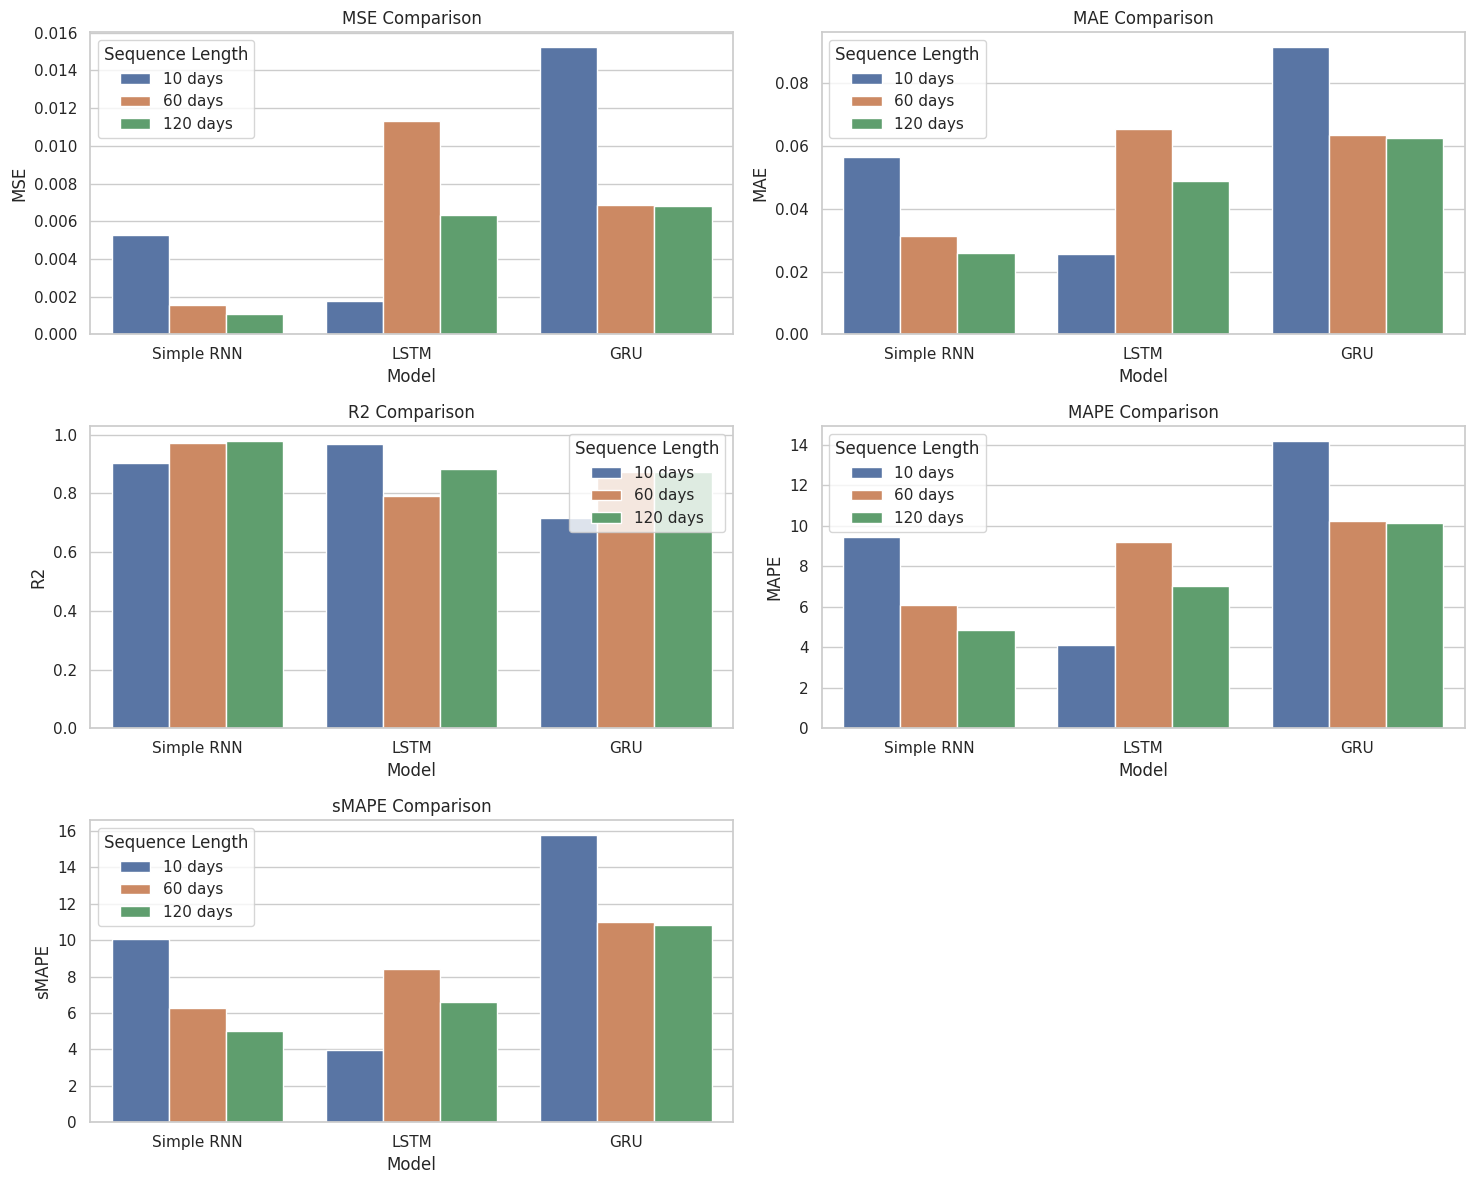

In [28]:
# Set up the Seaborn style
sns.set(style="whitegrid")

# Create a figure with subplots
fig, axes = plt.subplots(3, 2, figsize=(15, 12))

# Plot MSE
sns.barplot(x='Model', y='MSE', hue='Sequence Length', data=df, ax=axes[0, 0])
axes[0, 0].set_title('MSE Comparison')

# Plot MAE
sns.barplot(x='Model', y='MAE', hue='Sequence Length', data=df, ax=axes[0, 1])
axes[0, 1].set_title('MAE Comparison')

# Plot R2
sns.barplot(x='Model', y='R2', hue='Sequence Length', data=df, ax=axes[1, 0])
axes[1, 0].set_title('R2 Comparison')

# Plot MAPE
sns.barplot(x='Model', y='MAPE', hue='Sequence Length', data=df, ax=axes[1, 1])
axes[1, 1].set_title('MAPE Comparison')

# Plot sMAPE
sns.barplot(x='Model', y='sMAPE', hue='Sequence Length', data=df, ax=axes[2, 0])
axes[2, 0].set_title('sMAPE Comparison')

# Hide empty subplot
axes[2, 1].axis('off')

# Adjust layout
plt.tight_layout()
plt.show()